<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Описание" data-toc-modified-id="Описание-1"><span class="toc-item-num">1&nbsp;&nbsp;</span><strong>Описание</strong></a></span></li><li><span><a href="#Импорт-библиотек-и-настройка-среды" data-toc-modified-id="Импорт-библиотек-и-настройка-среды-2"><span class="toc-item-num">2&nbsp;&nbsp;</span><strong>Импорт библиотек и настройка среды</strong></a></span></li><li><span><a href="#Подготовка-данных" data-toc-modified-id="Подготовка-данных-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Подготовка данных</a></span></li><li><span><a href="#Классификация-текста-с-Google-Gemma-2-For-Sequence-Classification" data-toc-modified-id="Классификация-текста-с-Google-Gemma-2-For-Sequence-Classification-4"><span class="toc-item-num">4&nbsp;&nbsp;</span><strong>Классификация текста с <a href="https://huggingface.co/google/gemma-2-2b-it" target="_blank">Google Gemma-2 For Sequence Classification</a></strong></a></span><ul class="toc-item"><li><span><a href="#Загрузка-токенизатора-и-модели" data-toc-modified-id="Загрузка-токенизатора-и-модели-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Загрузка токенизатора и модели</a></span></li><li><span><a href="#Дообучение-LoRA-Gemma-2" data-toc-modified-id="Дообучение-LoRA-Gemma-2-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>Дообучение LoRA Gemma-2</a></span></li><li><span><a href="#Подбор-оптимального-порога-и-инференс" data-toc-modified-id="Подбор-оптимального-порога-и-инференс-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Подбор оптимального порога и инференс</a></span></li><li><span><a href="#Анализ-ошибок-модели" data-toc-modified-id="Анализ-ошибок-модели-4.4"><span class="toc-item-num">4.4&nbsp;&nbsp;</span>Анализ ошибок модели</a></span></li></ul></li><li><span><a href="#Результаты-и-выводы" data-toc-modified-id="Результаты-и-выводы-5"><span class="toc-item-num">5&nbsp;&nbsp;</span><strong>Результаты и выводы</strong></a></span></li></ul></div>

# Классификация комментариев

Этот ноутбук является обновлением [**предыдущего**](https://github.com/natashanoskova/ds_agents_hq/tree/main/006_troll_buster/006_troll_buster.ipynb "Перейти в предыдущий ноутбук"), выполненного классическими методами предобработки текстов и ML, и использует тот же набор данных.

##  **Описание**

**Задача:** построить модель для поиска и модерации токсичных комментариев к товарам в сервисе интернет-магазина.

Значение метрики качества модели **F1** должно быть **не меньше 0.75**.

В нашем распоряжении набор данных с разметкой о токсичности комментариев:
- **159 292** строки, **2** переменных
- пропусков и дубликатов нет
- колонка `text`  содержит текст комментария
- **`toxic`** — **целевой признак** токсичности: токсичный (1) / чистый (0)
- сильный дисбаланс классов **класс 0 ~ 90%, класс 1 ~ 10%**

## **Импорт библиотек и настройка среды**

In [1]:
!pip install -q huggingface_hub unsloth[colab-new]==2026.10.7
!unsloth install-kernels xformers

Unsloth: installed xformers (xformers-0.0.35-py39-none-manylinux_2_28_x86_64.whl).


In [2]:
import os
import re
import warnings
warnings.simplefilter(action='ignore')

import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', 1000)

from google.colab import userdata

import matplotlib.pyplot as plt
%config InlineBackend.figure_format='svg'

import torch
from datasets import Dataset
from unsloth import FastLanguageModel
from transformers import (
    set_seed,
    EarlyStoppingCallback,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE=0
set_seed(RANDOM_STATE)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [3]:
# проверяем, доступна ли видеокарта с поддержкой CUDA

if torch.cuda.is_available():
    print(f"Подключена видеокарта : {torch.cuda.get_device_name(0)}")
else:
    print("Видеокарта не подключена, проверьте настройки среды.")

Подключена видеокарта : Tesla T4


In [4]:
# передаем ключ-токен в систему

try:
    os.environ["HF_TOKEN"] = userdata.get('HF_TOKEN')
    print("Авторизация Hugging Face выполнена.")
except Exception:
    print("Ключ HF_TOKEN не найден в Секретах Colab.")

Авторизация Hugging Face выполнена.


In [5]:
# загрузка данных из рабочей директории Colab

pth = 'toxic_comments.csv'

if os.path.exists(pth):
  data = pd.read_csv(pth, index_col=0, engine='python', on_bad_lines='skip')
  print(f"Датасет загружен. Размер : {data.shape}")
else:
  print("Файла нет в хранилище Colab.")

Датасет загружен. Размер : (159292, 2)


В этом разделе выполняем установку необходимых библиотек для оптимизированного дообучения LLM. Важным элементом является использование библиотеки **Unsloth**, которая предоставляет xformers-ядра для моделей семейства Gemma-2, что позволяет выполнять вычисления в формате fp16 на видеокартах Tesla T4 без численной нестабильности и снижает потребление видеопамяти на ~60%.

## Подготовка данных

Так как исходный датасет обладает сильным дисбалансом, для обучения модели применяем метод контролируемого оверсэмплинга **Class-Targeted Splitting** меньшего класса в обучающей выборке.

- Обучающую выборку формируем в пропорции 30% токсичных / 70% чистых комментариев, объемом **30 000 строк**.
- В валидационной и тестовой выборках, каждая по **10 000 строк**, сохраняем исходное распределение классов для приближенной к реальности оценки качества.

In [6]:
#Проверяем, корректно ли загрузились данные

data.head(10)

,text,toxic
0,"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27",0
1,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, January 11, 2016 (UTC)",0
2,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instead of my talk page. He seems to care more about the formatting than the actual info.",0
3,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of """"types of accidents"""" -I think the references may need tidying so that they are all in the exact same format ie date format etc. I can do that later on, if no-one else does first - if you have any preferences for formatting style on references or want to do it yourself please let me know.\n\nThere appears to be a backlog on articles for review so I guess there may be a delay until a reviewer turns up. It's listed in the relevant form eg Wikipedia:Good_article_nominations#Transport """,0
4,"You, sir, are my hero. Any chance you remember what page that's on?",0
5,"""\n\nCongratulations from me as well, use the tools well. · talk """,0
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1
7,"Your vandalism to the Matt Shirvington article has been reverted. Please don't do it again, or you will be banned.",0
8,"Sorry if the word 'nonsense' was offensive to you. Anyway, I'm not intending to write anything in the article(wow they would jump on me for vandalism), I'm merely requesting that it be more encyclopedic so one can use it for school as a reference. I have been to the selective breeding page but it's almost a stub. It points to 'animal breeding' which is a short messy article that gives you no info. There must be someone around with expertise in eugenics? 93.161.107.169",0
9,alignment on this subject and which are contrary to those of DuLithgow,0


In [7]:
data.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
Index: 159292 entries, 0 to 159450
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    159292 non-null  object
 1   toxic   159292 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 79.7 MB


In [8]:
# Делаем случайную валидационную выборку, фиксируем random_state для воспроизводимости

temp_data, val_data = train_test_split(
    data, test_size=10000, random_state=RANDOM_STATE, stratify=data["toxic"]
)
print("Размер валидационной выборки :", val_data.shape)
print("\nБаланс классов в валидационной выборке :")
display(val_data.toxic.value_counts(normalize=1))

Размер валидационной выборки : (10000, 2)

Баланс классов в валидационной выборке :


,proportion
toxic,
0,0.8984
1,0.1016


In [9]:
# Делаем случайную тестовую выборку, фиксируем random_state для воспроизводимости

train_pool, test_data = train_test_split(
    temp_data, test_size=10000, random_state=RANDOM_STATE, stratify=temp_data["toxic"]
)
print("Размер тестовой выборки :", test_data.shape)
print("\nБаланс классов в тестовой выборке :")
display(test_data.toxic.value_counts(normalize=1))

Размер тестовой выборки : (10000, 2)

Баланс классов в тестовой выборке :


,proportion
toxic,
0,0.8984
1,0.1016


In [10]:
# Разделяем пул на токсичные и чистые строки

toxic_pool = train_pool[train_pool['toxic'] == 1]
clean_pool = train_pool[train_pool['toxic'] == 0]

# Создаем выборку в 30000 строк в соотношении 30% токсичных, 70% чистых комментариев

toxic_sampled = toxic_pool.sample(n=9000, random_state=RANDOM_STATE)
clean_sampled = clean_pool.sample(n=21000, random_state=RANDOM_STATE)

# Соединяем их вместе и перемешиваем
train_data = pd.concat([clean_sampled, toxic_sampled]).sample(frac=1, random_state=RANDOM_STATE)

print('Размер обучающей выборки :', train_data.shape)
print('\nБаланс классов в обучающей выборке :')
display(train_data.toxic.value_counts(normalize=1))

Размер обучающей выборки : (30000, 2)

Баланс классов в обучающей выборке :


,proportion
toxic,
0,0.7
1,0.3


In [11]:
# Считаем длину комментариев в словах для полученных выборок
words_train = train_data["text"].astype(str).str.split().str.len()
words_val = val_data["text"].astype(str).str.split().str.len()
words_test = test_data["text"].astype(str).str.split().str.len()

# Извлекаем статистику и преобразуем в датафреймы
desc_train = words_train.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame().T
desc_val = words_val.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame().T
desc_test = words_test.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame().T

# Добавляем название выборки как индекс строк
desc_train.index = ["Обучающая выборка"]
desc_val.index = ["Валидационная выборка"]
desc_test.index = ["Тестовая выборка"]

# Объединяем строки в общую таблицу
desc = pd.concat([desc_train, desc_val, desc_test])

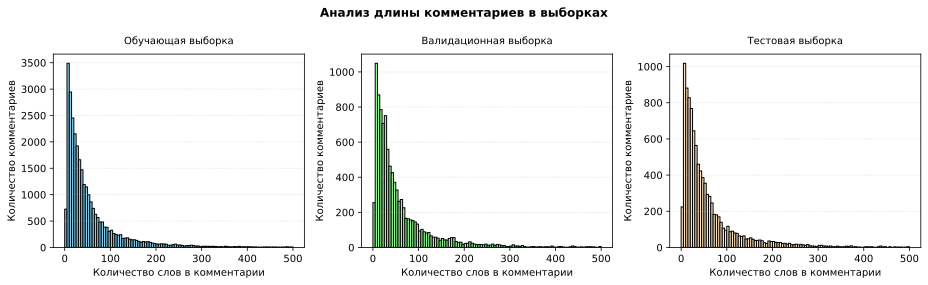


📊 СВОДНАЯ СТАТИСТИКА ДЛИНЫ КОММЕНТАРИЕВ В ВЫБОРКАХ:



,count,mean,std,min,25%,50%,75%,90%,95%,max
Обучающая выборка,30000.0,65.0856,102.126005,1.0,15.0,33.0,71.0,145.0,223.0,1354.0
Валидационная выборка,10000.0,66.3868,97.693377,1.0,16.0,35.0,75.0,152.0,225.0,1104.0
Тестовая выборка,10000.0,66.7419,100.308492,2.0,17.0,35.0,72.0,151.0,228.0,1411.0


In [12]:
# Строим графики выборок
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4))

# Ограничиваем диапазон до 500 слов для наглядности
plot_range = (0, 500)
bins_count = 100

ax1.hist(words_train, bins=bins_count, color='skyblue', edgecolor='black', range=plot_range)
ax1.set_title('Обучающая выборка', fontsize=10, pad=10)
ax1.set_xlabel('Количество слов в комментарии')
ax1.set_ylabel('Количество комментариев')
ax1.grid(axis='y', alpha=0.5, linestyle=':')

ax2.hist(words_val, bins=bins_count, color='palegreen', edgecolor='black', range=plot_range)
ax2.set_title('Валидационная выборка', fontsize=10, pad=10)
ax2.set_xlabel('Количество слов в комментарии')
ax2.set_ylabel('Количество комментариев')
ax2.grid(axis='y', alpha=0.5, linestyle=':')

ax3.hist(words_test, bins=bins_count, color='bisque', edgecolor='black', range=plot_range)
ax3.set_title('Тестовая выборка', fontsize=10, pad=10)
ax3.set_xlabel('Количество слов в комментарии')
ax3.set_ylabel('Количество комментариев')
ax3.grid(axis='y', alpha=0.5, linestyle=':')

fig.suptitle('Анализ длины комментариев в выборках', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Выводим итоговую сводную таблицу
print("\n📊 СВОДНАЯ СТАТИСТИКА ДЛИНЫ КОММЕНТАРИЕВ В ВЫБОРКАХ:\n")
display(desc)

Перед токенизацией для корректного выбора величины параметра ограничения максимальной длины контекста `max_seq_length` проведена оценка длины комментариев (в словах) в обучающей, валидационной и тестовой выборках.

**Вывод по анализу длин комментариев:**
- средняя длина комментария составляет около 66 слов,
- 95% всех комментариев в обеих выборках не превышают длины в **223-228 слов**, тем не менее, есть очень длинные комментарии,
- 1 слово на английском языке у токенизатора Gemma превращается примерно в 1.25–1.35 токена, ограничение `max_seq_length=512` токенов будет оптимально, чтобы покрыть > 95% комментариев без потери важного контекста из-за обрезки и при этом оптимизировать использование памяти GPU.

## **Классификация текста с [Google Gemma-2 For Sequence Classification](https://huggingface.co/google/gemma-2-2b-it)**

Для решения задачи бинарной классификации токсичных комментариев используем **Gemma-2-2B-It**, современную легковесную LLM от Google, содержащую 2,6 миллиарда параметров.

Поскольку базовая модель Causal LM предназначена для генерации текста, переводим её в режим **Sequence Classification:**

- **удаляется генеративная «голова»** модели,
- **добавляется новый классификационный слой** размерностью `num_labels=2`, модель учится агрегировать скрытое состояние последнего значащего токена в логиты двух классов: `0` и `1`.


### Загрузка токенизатора и модели

Загружаем базовую модель **google/gemma-2-2b-it** с 4-битным квантованием **QLoRA**. Это позволит запустить дообучение на видеокарте Tesla T4 без риска получить ошибку нехватки памяти.

In [13]:
# Максимальная длина последовательности на основе проведенного EDA 512 токенов
max_seq_length = 512

In [14]:
# Загружаем предобученную модель и токенизатор через Unsloth

model_cls, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "google/gemma-2-2b-it",
    max_seq_length = max_seq_length,
    load_in_4bit = True,   # 4-битное квантование для T4
    num_labels = 2,        # Бинарная классификация
)

==((====))==  Unsloth 2026.10.7: Fast Gemma2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not planning a device map; the load builds Gemma2ForSequenceClassification, not the planned Gemma2ForCausalLM. Using `sequential`.


Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

Gemma2ForSequenceClassification LOAD REPORT from: unsloth/gemma-2-2b-it-bnb-4bit
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Unsloth: Will load unsloth/gemma-2-2b-it-bnb-4bit as a legacy tokenizer.


In [15]:
# Настраиваем pad_token
tokenizer.pad_token = tokenizer.eos_token

# Настройка для стабильности эмбеддингов в 4-бит
model_cls.config.pad_token_id = tokenizer.pad_token_id

**Конвертация данных и динамический паддинг:**

- Для корректной работы Trainer, переводим данные из формата Pandas DataFrame в в оптимизированный формат `Hugging Face Dataset`.
- Колонку целевого признака `toxic` переименовываем в `labels` согласно спецификации класса `AutoModelForSequenceClassification`.
- На этапе токенизации мы намеренно отключаем жесткий паддинг внутри функции, перенося эту задачу на уровень сборщика батчей.

In [16]:
# В выборках оставляем только текст комментария и метку класса
train_ds = Dataset.from_pandas(
    train_data[['text', 'toxic']].rename(columns={'toxic': 'labels'}).reset_index(drop=True)
)

val_ds = Dataset.from_pandas(
    val_data[['text', 'toxic']].rename(columns={'toxic': 'labels'}).reset_index(drop=True)
)

test_ds = Dataset.from_pandas(
    test_data[['text', 'toxic']].rename(columns={'toxic': 'labels'}).reset_index(drop=True)
)

    # токенизируем текст, обрезаем длинные комментарии до 512 токенов
    # padding=False - будем выравнивать длину на уровне батча с помощью DataCollator
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=max_seq_length, padding=False)


# Применяем токенизацию к выборкам
train_ds_tknz = train_ds.map(tokenize_function, batched=True)
val_ds_tknz = val_ds.map(tokenize_function, batched=True)
test_ds_tknz = test_ds.map(tokenize_function, batched=True)

Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

### Дообучение LoRA Gemma-2

Для адаптации модели **Gemma-2** под задачу классификации применяется метод **PEFT (Parameter-Efficient Fine-Tuning)** с использованием алгоритма **LoRA (Low-Rank Adaptation)**. Вместо изменения всех 2,6 миллиардов параметров базовой модели, основные веса "замораживаются", а обучаются только небольшие встроенные слои-адаптеры.

Поскольку для дообучения используется библиотека Unsloth, явный импорт peft и ручная сборка конфигурации в коде не требуются. Unsloth автоматически настраивает и инициализирует LoRA-адаптеры "под капотом" с помощью функции `FastLanguageModel.get_peft_model()`.

**Как настроено обучение:**
- *Экономия ресурсов:* адаптеры добавлены во все линейные слои модели `q, k, v, o, gate, up, down_proj` с параметрами `r=32` и `lora_alpha=64`. В итоге мы обучаем всего ~0.79% параметров, что актуально при использовании Tesla T4.
- *Стабилизация шага:* скорость обучения `8e-5` с косинусным планировщиком и плавным разогревом `warmup_steps=0.1` в первые 10% шагов.
- *Защита от переобучения:* оценка на валидации запускается каждые 50 шагов. Если в течение 3 проверок подряд лосс на валидации перестает падать, обучение автоматически остановится.
- *Мониторинг:* Все графики и метрики в реальном времени транслируются в TensorBoard и сохраняются в репозитории Hugging Face.

In [17]:
# Настройка адаптера через Unsloth

model_cls = FastLanguageModel.get_peft_model(
    model_cls,
    r = 32,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha = 64,
    lora_dropout = 0,    # В Unsloth dropout должен быть 0 для максимальной скорости
    bias = "none",
)

Unsloth 2026.10.7 patched 26 layers with 26 QKV layers, 26 O layers and 26 MLP layers.


In [18]:
training_args_cls = TrainingArguments(
    output_dir="./gemma_toxic_classification",
    per_device_train_batch_size=16,    # Итоговый батч = 16 х 2 = 32
    gradient_accumulation_steps=2,
    learning_rate=8e-5,
    lr_scheduler_type="cosine",
    warmup_steps=0.1,
    max_steps=1000,
    optim="paged_adamw_8bit",
    fp16=True,                        # Unsloth обеспечит стабильность fp16
    bf16=False,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=50,                    # Проверяем модель каждые 50 шагов
    report_to="tensorboard",
    push_to_hub=False,
    hub_model_id="nnl26/gemma-2-toxic-classification",
    hub_private_repo=True,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="loss",     # Ориентируемся на лосс валидации
    greater_is_better=False
)

In [19]:
# Создаем сборщик батчей, который автоматически сделает паддинг

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [20]:
# Функция для расчета F1

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Во время промежуточных шагов обучения используем стандартный argmax, порог 0.5
    predictions = np.argmax(logits, axis=-1)
    # Считаем F1 для токсичного класса pos_label=1
    f1 = f1_score(labels, predictions, average="binary", pos_label=1)
    return {"eval_f1_threshold_0.5": f1}

In [21]:
# Запуск стандартного Trainer

trainer_cls = Trainer(
    model=model_cls,
    args=training_args_cls,
    train_dataset=train_ds_tknz,
    eval_dataset=val_ds_tknz,
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

In [22]:
print("Запускаем обучение Gemma-2 через Unsloth...\n")

trainer_cls.train()

print("Обучение завершено ✅")

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 30,000 | Num Epochs = 2 | Total steps = 1,000
O^O/ \_/ \    Batch size per device = 16 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (16 x 2 x 1) = 32
 "-____-"     Trainable parameters = 41,538,048 of 2,655,884,544 (1.56% trained)
Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma2ForSequenceClassification's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


Запускаем обучение Gemma-2 через Unsloth...

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss,F1 Threshold 0.5
50,0.370198,0.289290,0.638957
100,0.215811,0.304189,0.670908
150,0.246448,0.101903,0.806813
200,0.125356,0.097757,0.827306
250,0.204138,0.085372,0.832507
300,0.173447,0.361024,0.610386
350,0.143244,0.097148,0.835278
400,0.198963,0.131582,0.778053


Unsloth: Restored added_tokens_decoder metadata in ./gemma_toxic_classification/checkpoint-50/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_toxic_classification/checkpoint-50.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_toxic_classification/checkpoint-100/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_toxic_classification/checkpoint-100.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_toxic_classification/checkpoint-150/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_toxic_classification/checkpoint-150.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_toxic_classification/checkpoint-200/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_toxic_classification/checkpoint-200.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_toxic_classification/checkpoint-250/tokenizer_confi

Обучение завершено ✅


In [ ]:
trainer_cls.push_to_hub(commit_message="Training completed")

Unsloth: Restored added_tokens_decoder metadata in ./gemma_toxic_classification/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_toxic_classification.


CommitInfo(commit_url='https://huggingface.co/nnl26/gemma-2-toxic-classification/commit/2ffae2056126420b0d52aee8f849f2801372d658', commit_message='Training completed', commit_description='', oid='2ffae2056126420b0d52aee8f849f2801372d658', pr_url=None, repo_url=RepoUrl('https://huggingface.co/nnl26/gemma-2-toxic-classification', endpoint='https://huggingface.co', repo_type='model', repo_id='nnl26/gemma-2-toxic-classification'), pr_revision=None, pr_num=None)

In [23]:
# Извлекаем историю обучения из логов тренера

history = trainer_cls.state.log_history

# Берем те шаги, где рассчитывался Training Loss
train_loss_data = [log for log in history if "loss" in log]

# Переводим данные в таблицу Pandas DataFrame
# добавляем линию тренда / скользящее среднее
df_loss = pd.DataFrame(train_loss_data)
df_loss['smooth_loss'] = df_loss['loss'].rolling(window=3, min_periods=1, center=True).mean()

In [24]:
# Получаем отдельно данные для валидационного лосса

eval_loss_data = [log for log in history if "eval_loss" in log]
df_eval_loss = pd.DataFrame(eval_loss_data)

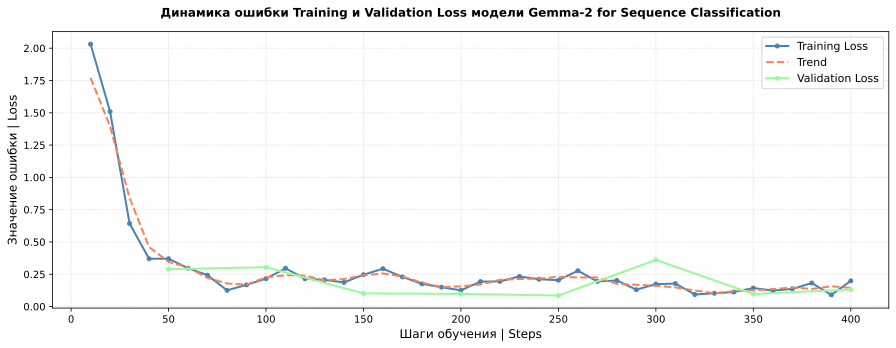

In [25]:
# Строим график изменения ошибки

plt.figure(figsize=(15, 5))

plt.plot(df_loss['step'], df_loss['loss'], label='Training Loss',
         color='steelblue', linewidth=2, marker='o', markersize=4)

plt.plot(df_loss['step'], df_loss['smooth_loss'], label='Trend',
         color='coral', linestyle='--', linewidth=2)

plt.plot(df_eval_loss["step"], df_eval_loss["eval_loss"], label="Validation Loss",
         color="palegreen", linewidth=2, marker="o", markersize=4)

plt.title('Динамика ошибки Training и Validation Loss модели Gemma-2 for Sequence Classification',
          fontsize=12, pad=15, fontweight='bold')
plt.xlabel('Шаги обучения | Steps', fontsize=12)
plt.ylabel('Значение ошибки | Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc="upper right")

plt.show()

**Анализ результатов обучения и метрик:**

- Сходимость модели: стартовый лосс в районе ~2.0 стремительно падает и стабилизируется уже к 50-му шагу ниже уровня 0.4, что говорит о хорошей адаптивности архитектуры модели к текстовой классификации через LoRA-адаптеры.
- Наилучшее качество модели: минимальный **Validation Loss = 0.0853** и высокий **F1-Score = 0.8325** достигается на **250-м шаге.**
- На 300-м шаге наблюдается резкий скачок валидационного лосса вверх до 0.3610 при одновременном падении метрики F1 до 0.6103, что может говорить о локальном переобучении под специфический батч.
- К 350-му шагу модель скорректировала траекторию, вернувшись к низкому лоссу и высокому F1, однако на 400-м шаге валидационная ошибка снова пошла вверх, в то время как тренировочный лосс продолжал монотонно снижаться.
- Заданный в параметрах колбэк `early_stopping_patience=3` предовратил дальнейшее переобучение модели. Так как после лучшей точки на 250-м шаге валидационный лосс не обновил свой минимум на следующих 300, 350 и 400 шагах, процесс обучения завершился досрочно.
- Благодаря параметру `load_best_model_at_end=True` в финальный ансамбль переданы веса лучшего результата с 250-го шага.

### Подбор оптимального порога и инференс

In [26]:
# Переводим сырые выходы модели в вероятности от 0 до 1 с помощью функции Softmax

def softmax(x):
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / e_x.sum(axis=-1, keepdims=True)

In [27]:
# Получаем предсказания модели на валидационной выборке

val_predictions = trainer_cls.predict(val_ds_tknz)

# Получаем матрицу вероятностей, где второй столбец — вероятность токсичности
val_probabilities = softmax(val_predictions.predictions)
val_probs = val_probabilities[:, 1]

# Перебираем разные пороги от 0.1 до 0.92
print("Ищем оптимальный порог:")

best_f1 = 0
best_threshold = 0.1
thresholds = np.arange(0.1, 0.92, 0.02)

for threshold in thresholds:
    # если вероятность выше порога — ставим 1, иначе 0
    temp_preds = (val_probs >= threshold).astype(int)
    current_f1 = f1_score(val_data['toxic'], temp_preds)
    print(f"Порог: {threshold:.2f} | Итоговый F1-score: {current_f1:.4f}")

    if current_f1 > best_f1:
        best_f1 = current_f1
        best_threshold = threshold

print(f"\nСамый высокий F1 = {best_f1:.4f} достигается при пороге {best_threshold:.2f}")

Ищем оптимальный порог:
Порог: 0.10 | Итоговый F1-score: 0.7570
Порог: 0.12 | Итоговый F1-score: 0.7695
Порог: 0.14 | Итоговый F1-score: 0.7780
Порог: 0.16 | Итоговый F1-score: 0.7874
Порог: 0.18 | Итоговый F1-score: 0.7932
Порог: 0.20 | Итоговый F1-score: 0.8005
Порог: 0.22 | Итоговый F1-score: 0.8063
Порог: 0.24 | Итоговый F1-score: 0.8116
Порог: 0.26 | Итоговый F1-score: 0.8147
Порог: 0.28 | Итоговый F1-score: 0.8186
Порог: 0.30 | Итоговый F1-score: 0.8188
Порог: 0.32 | Итоговый F1-score: 0.8240
Порог: 0.34 | Итоговый F1-score: 0.8267
Порог: 0.36 | Итоговый F1-score: 0.8299
Порог: 0.38 | Итоговый F1-score: 0.8324
Порог: 0.40 | Итоговый F1-score: 0.8333
Порог: 0.42 | Итоговый F1-score: 0.8339
Порог: 0.44 | Итоговый F1-score: 0.8333
Порог: 0.46 | Итоговый F1-score: 0.8344
Порог: 0.48 | Итоговый F1-score: 0.8323
Порог: 0.50 | Итоговый F1-score: 0.8325
Порог: 0.52 | Итоговый F1-score: 0.8337
Порог: 0.54 | Итоговый F1-score: 0.8324
Порог: 0.56 | Итоговый F1-score: 0.8343
Порог: 0.58 | Ит

In [28]:
# Применяем оптимальный порог
# если вероятность >= 0.46, то класс 1 (Toxic), иначе 0 (Clean)

val_preds = (val_probs >= best_threshold).astype(int)

# Получаем валидационный лосс напрямую из метрик
val_loss = val_predictions.metrics['test_loss']

# Выводим отчет для лучшего порога
print(f"\n Средний Loss на валидационной выборке : {val_loss:.4f}")
print(f"\n📊 Метрики на валидационной выборке при лучшем пороге {best_threshold:.2f} :\n")
print(classification_report(val_data['toxic'], val_preds, target_names=['Clean (0)', 'Toxic (1)']))


 Средний Loss на валидационной выборке : 0.0854

📊 Метрики на валидационной выборке при лучшем пороге 0.46 :

              precision    recall  f1-score   support

   Clean (0)       0.98      0.98      0.98      8984
   Toxic (1)       0.83      0.84      0.83      1016

    accuracy                           0.97     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.97      0.97      0.97     10000



Матрица ошибок на валидационной выборке, оптимальный порог 0.46.


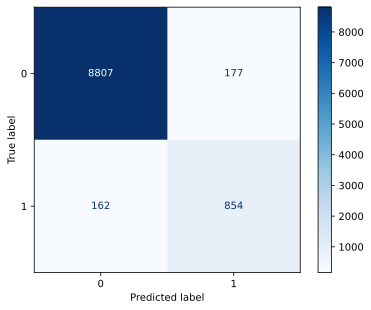

In [29]:
# Выводим матрицу ошибок на валидационной выборке
print(f"Матрица ошибок на валидационной выборке, оптимальный порог {best_threshold:.2f}.")

ConfusionMatrixDisplay(confusion_matrix(val_data['toxic'], val_preds)).plot(cmap='Blues');

Так как стандартный порог разделения классов 0,5 не всегда идеален, особенно когда данные несбалансированы, подобран порог, при котором метрика баланса точности и полноты **F1-score** максимальна.
- На валидационной выборке получили логиты модели и преобразовали в вероятности с помощью функции Softmax.
- Перебрали пороги вероятности от 0,1 до 0,92 с шагом 0,02.
- При оптимальном пороге **0,46** на *валидационной выборке* модель показала лучший **`F1 = 0.8344`**.

In [30]:
# Получаем предсказания модели на тестовой выборке

test_predictions = trainer_cls.predict(test_ds_tknz)

# Получаем матрицу вероятностей, где второй столбец — вероятность токсичности
test_probabilities = softmax(test_predictions.predictions)
test_probs = test_probabilities[:, 1]

# Применяем оптимальный порог 0.46 на тестовой выборке
# если вероятность >= 0.46, то класс 1 (Toxic), иначе 0 (Clean)
test_preds = (test_probs >= best_threshold).astype(int)

# Перезаписываем результат предсказаний
test_data['gemma_pred'] = test_preds

f1 = f1_score(test_data['toxic'], test_preds)

# Получаем тестовый лосс из метрик
test_loss = test_predictions.metrics['test_loss']

# Выводим финальный отчет для лучшего порога
print(f"\n Средний Loss на тестовой выборке : {test_loss:.4f}")
print(f"\n Итоговая F1-мера для модели Gemma-2 : {f1:.4f}")
print(f"\n📊 Метрики на тестовой выборке при лучшем пороге {best_threshold:.2f} :\n")
print(classification_report(test_data['toxic'], test_preds, target_names=['Clean (0)', 'Toxic (1)']))


 Средний Loss на тестовой выборке : 0.0928

 Итоговая F1-мера для модели Gemma-2 : 0.8300

📊 Метрики на тестовой выборке при лучшем пороге 0.46 :

              precision    recall  f1-score   support

   Clean (0)       0.98      0.98      0.98      8984
   Toxic (1)       0.84      0.82      0.83      1016

    accuracy                           0.97     10000
   macro avg       0.91      0.90      0.91     10000
weighted avg       0.97      0.97      0.97     10000



Матрица ошибок на тестовой выборке, оптимальный порог 0.46.


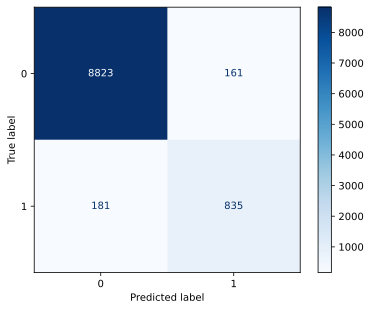

In [31]:
# Выводим матрицу ошибок для тестовой выборки
print(f"Матрица ошибок на тестовой выборке, оптимальный порог {best_threshold:.2f}.")

ConfusionMatrixDisplay(confusion_matrix(test_data['toxic'], test_preds)).plot(cmap='Blues');

**Итоговые метрики на тесте:**
- Средний Loss : 0.0928
- Итоговый **F1-score : 0.8300**
- Общая точность (Accuracy) : 97%

**Класс 0** (обычные комментарии): Precision — 98%, Recall — 98%. Модель безошибочно находит чистые комментарии и почти никогда не путает их с токсичными.

**Класс 1** (токсичные комментарии): Precision — 84%, Recall — 82%. Модель находит 82% всего токсичных коментариев, если отмечает комментарий как токсичный, то в 84% случаев оказывается права.

Разница между значениями F1-score на валидации и тесте очень мала - менее половины процента. Это доказывает, что модель не переобучилась.

### Анализ ошибок модели

Чтобы понять, где именно модель ошибается, выведем примеры расхождений между исходной разметкой `toxic` и предсказаниями модели `gemma_pred`.

In [32]:
# Возьмем случаи, где отметка 1, а модель ответила 0

false_negatives = test_data.query('toxic == 1 and gemma_pred == 0')

print(f"Найдено расхождений : {len(false_negatives)} из {len(test_data)}")
false_negatives[['text', 'toxic', 'gemma_pred']].head(10)

Найдено расхождений : 181 из 10000


,text,toxic,gemma_pred
61442,"""\n\n First point - it was not only treated as mental illness, but as criminal activity.\n Second point - you should only refer to 'homosexual romance' in the lead if there is a section that deals with 'homosexual romance' in the body of the text, as the lead is a summary of what is in the body, and having ten sources does not count for much unless the terms are unpacked somewhere in the main text. All these seem to show is that people like Giddens (who is a notable sociologist, but no authority on sexuality, sexology, LGBT studies in general or homosexuality in particular) use the term. If there were a link to an article Homosexual romance, which shows the term can be taken for granted, fine - otherwise it needs to be dealt with in the article before it can be inserted into the lead. \n Third point, my earlier comment about this was made with ironic and humorous intent, because I have only come across the term 'romance' used in this context, at conferences, ironically or critic...",1,0
19608,"""\n\nturk! turks occupied it and today are drinking the blood of Kurdish people. Talk + """,1,0
141907,"Well, you might not be welcoming me if you knew what my other account was. It's called I Condemn Homosexuality. The edit filter totally stopped me from making any edits with that account, so it seems to be working well.",1,0
112874,"Gee, Dreambarf, visitors will come slowly, not all in one day, and EB is not liked by \nthe great unwashed majority of Bigfoot fans, who are only one step over Wiki admins in IQ.\nIntelligent people in the Bigfoot field, about ten, are continually trashed on the net by\nlosers,drop outs and good ol boyz with gunracks and six packs. WHY DON'T YOU KNOW THIS?\nBecause you are too busy fighting off those who DO NOT LIKE YOU over at your own userpage, and the pages you started. Lots of Wiki people do not like you, dude. Not just me... lots of others.\nI see it, I read it. It is true. Back in 1606 or whatever, YOU would have burned Galileo.\n\nJeff.",1,0
79822,"Samantha555, in case you haven't noticed, this power-mad user pulls this nonsense a lot",1,0
52513,"Yes, I took my sword and attacked you by trying to chop off your head, but that didn't help because of the hydra that you are. One head off, two new appear. One step forward, two steps behind. Thanks for your message.",1,0
26888,"Utter nonsense, Hullaballoo. Mine are sharp, critical responses, NOT personal attacks. Don't be so excessively sensitive.",1,0
41477,"KInkaid Stinks \n\nKinkaid is a school that not only captures and uses the student as slaves, but also turns thier blood into energy",1,0
30933,"You protect the pages from my edits, not because there is anything wrong with my edits, but because you have a personal vendetta against me. It's pathetic. I will restore those edits in mid-January, not because I hold a grudge against youwhich I don'tbut because they should be there, and they are helpful to regular users. 82.132.222.244",1,0
82188,SERIOUSLY \n\nAS SOON ASI'M UNBANENED I WLL WREACFK EVERYTHING,1,0


In [33]:
# Возьмем случаи, где отметка 0, а модель поставила 1

false_positives = test_data.query('toxic == 0 and gemma_pred == 1')

print(f"Найдено расхождений : {len(false_positives)} из {len(test_data)}")
false_positives[['text', 'toxic', 'gemma_pred']].head(10)

Найдено расхождений : 161 из 10000


,text,toxic,gemma_pred
2675,"warning\nI read it. I'll consider it. I deleted it. Its my talk page, I'll do as I please with it. Quit being a fascist.",0,1
46756,"Okay why the hell are we sweeping the tese tragic events under the rug? \n\nthe hurrican in florirda, the tsunami in indonesia, the flooding of new orleans, etc. ?",0,1
35548,"OMG, I'm your biggest fan you old goat",0,1
53674,"Wow, god, can you get him to wake up and realize the hell i've been in?!",0,1
38966,"WTF IS THIS \n\nI come here to learn and I get told I can not. The date is Oct 7th, and I missed it. I guess I'll just have to google it and spread it around the internet. OK bye.",0,1
22793,"About [Sitush] \n\nArrogant-believes, his arguments and references are best, Illogical- he cant digest logical evidence- still trying to get the biology definition in Math book: Eg; has written about khatris origin from Dashrath Sharma on Rajputs book, idiot- cant understand references and read them, racist (https://en.wikipedia.org/wiki/Racism) you come under this definition, \n\nStill if you have some shame left in you, quit wikipedia or start listening/discussing.",0,1
136561,Who you are to tell anything about some nationalistic nonsense? smells very russian-soviet. don't disclose yourself agent KGB Vanya!,0,1
48938,Completely garbage article. \n\nHuge amount of POV.,0,1
9611,"LoL Breein1007 you little troll. Tell me, with all that time you spend patronizing adult websites pretending you have a girlfriend, how do you find the time to flame wiki talk pages? I think what I find most patheticly amusing about you, is that you get some kind of lift out of your trollishness. Ahhh... Breein1007... You have no idea what rules or consequences actually are. Keep cruising mate.... If you decide you want to grow up, give me a shout. I'll be happy to work with you.",0,1
34182,"""\n\nWhat did I not spell correctly you prick? I never have used the term """"Charlottan""""\n\n""",0,1


**Наблюдение по качеству данных:**

Хотя нам не известно по каким правилам производилась первоначальная разметка, при ручном анализе примеров стало очевидно, что во многих случаях права именно модель, а не исходная разметка, либо оценку комментария можно отнести к так называемой "серой зоне" модерации.

**False Positives** модель выявила в данных прямую токсичность, включая грубые оскорбления личности, гомофобный хейт-спич, которые явно ошибочно помечены в исходном датасете как "чистые" / `toxic=0`.

**False Negatives** модель проигнорировала триггерные слова, когда они являлись частью цитирования внешних источников или новостных статей. Среди комментариев часто встречаются длинные эмоциональные споры, обсуждения исторических или политических тем, где есть резкие слова, но нет прямой токсичности и явных нарушений. Модель уловила этот контекст, а разметчики поставили `toxic=1`, вероятно, по триггерным словам.

## **Результаты и выводы**

- Замена стандартного BitsAndBytes на фреймворк **Unsloth** позволила работать с форматом `fp16` на старой архитектуре GPU Tesla T4, расширить контекст до `512 токенов`, что снизило "слепоту" модели на длинных комментариях, и увеличить размер батча до 32.

-  Сочетание Unsloth + LoRA позволило получить хорошее качество классификации **F1 = 0.83**, задействовав весьма скромные ресурсы.

- Изменение пропорции обучающей выборки на 30% токсичных и 70% чистых строк дало модели 9000 примеров англоязычного сленга и оскорблений и позволило модели лучше понять специфику данного датасета, при этом сохранилось преобладание чистых текстов.

- Косинусный планировщик в сочетании с `learning_rate=8e-5` позволил модели более глубоко оптимизировать веса. Early Stopping сработала на **400 шаге**, автоматически откатив веса к точке минимума лосса на **250 шаге**, предохранив результат от переобучения. Метрики на валидации и тесте практически идентичны. Более того, анализ ошибок показал, что реальное качество модели даже выше тестовых метрик, так как она игнорирует ошибки в исходных данных.

- Одна из проблем, препятствующих повышению F1-меры это качество исходных данных. Такие исследования, как проект Cleanlab от MIT, показали, что в стандартных текстовых датасетах содержится от 3% до 5% ошибок в разметке. Из-за этого шума модель упирается в "потолок" по качеству, и не может набрать близкий к 100% результат, потому что алгоритм наказывают за правильные и логичные предсказания там, где разметка ошибочна.

- Разработанный пайплайн универсален, его можно применять для любых других задач текстовой классификации.

Итоговые веса обученных LoRA-адаптеров и конфигурационные файлы сохранены и доступны здесь: **[карточка модели на Hugging Face 🤗](https://huggingface.co/nnl26/gemma-2-toxic-classification "Перейти на Hugging Face")**